# Equações Diferenciais Parciais

In [ ]:
import numpy as np
import matplotlib.pylab as plt
plt.rcParams['figure.figsize'] = [15,7]

    Algumas das PDE's que se podem resolver :
    
    1. Equação de onda
    2. Equação da difusão
    3. Equação de Laplace
    4. Equação de Poisson
    5. Equações de Maxwell
    6. Equação de Schrödinger

## Boundary value problemas

<br>
$$ \Large \textrm{Resolução da Equação de Laplace em 2D}$$

***

$$\large \frac{\partial ² \phi}{\partial x²} + \frac{\partial ² \phi}{\partial y²} = 0 \\ $$ 

    Estas segundas derivadas parciais podem ser escritas como : 
<br> 
$$ \large \frac{\partial ² \phi}{\partial x²} + \frac{\partial ² \phi}{\partial y²}
= \frac{ \phi(x+a,y) + \phi(x-a,y) + \phi(x,y+a) + \phi(x,y-a) - 4\phi(x,y)}{a²} \\ $$ 

    sendo que o termo 'a' é equivalente ao termo h que frequentemente se vê na definição de derivada num ponto 
    
$$ \large f '(x) = \lim_{h \to 0} \frac{f(x+h) - f(x)}{h}$$
<br>
    
    só que neste caso 'a' corresponde à distância entre os pontos da matriz que é constituída pelos valores de 

$ \phi(x,y). $

    Desta forma a Equação de Laplace toma a seguinte forma : 

$$ \\ \large \phi(x+a,y) + \phi(x-a,y) + \phi(x,y+a) + \phi(x,y-a) - 4\phi(x,y) = 0 $$

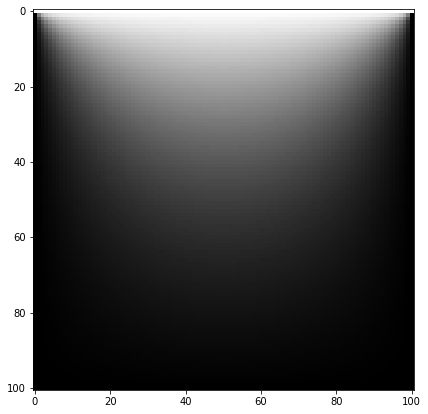

In [ ]:
def Laplace():
    
    # Constantes
    M = 100
    V = 1.0
    target = 1e-6
    dif = 1
    
    # Arrays necessários
    phi = np.zeros([M+1, M+1])
    phi[0,:] = V
    phil = np.copy(phi)
    
    while dif > target:
        
        for i in range(1,M):
            for j in range(1,M):
                phil[i,j] = (phi[i+1,j] + phi[i-1,j] + phi[i,j+1] + phi[i,j-1])/4
                
        dif = np.max(abs(phi-phil))

        phi,phil = phil,phi
    
    plt.imshow(phi)
    plt.gray()
    plt.show()

Laplace()

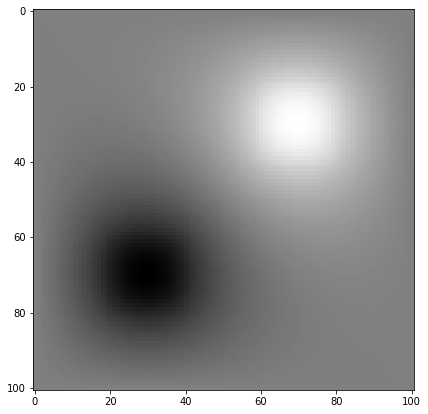

In [ ]:
def Poisson():
    
    # Constantes
    M = 100
    V = 1.0
    target = 1e-6
    dif = 1
    
    # Arrays necessários
    phi = np.zeros([M+1, M+1])
    rho = np.copy(phi)
    rho[20:40,60:80] = 1
    rho[60:80,20:40] = -1
    phil = np.copy(phi)
    
    while dif > target:
        
        for i in range(1,M):
            for j in range(1,M):
                phil[i,j] = (phi[i+1,j] + phi[i-1,j] + phi[i,j+1] + phi[i,j-1])/4 + 1/4*rho[i,j]
                
        dif = np.max(abs(phi-phil))

        phi,phil = phil,phi
    
    plt.imshow(phi)
    plt.gray()
    plt.show()

Poisson()

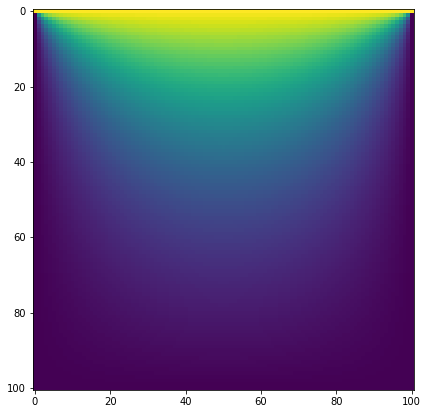

In [ ]:
def GaussSeidel_Laplace():
    
    # Constantes
    M = 100
    V = 1.0
    target = 1e-6
    dif = 1
    
    # Arrays necessários
    phi = np.zeros([M+1, M+1])
    phi[0,:] = V
    w = 0.9
    
    while dif > target:
        dif = 0
        
        for i in range(1,M):
            for j in range(1,M):
                
                diferenca = (phi[i+1,j] + phi[i-1,j] + phi[i,j+1] + phi[i,j-1])/4 - phi[i,j]
                phi[i,j] = phi[i,j] + (1+w)*diferenca
                
                if diferenca > dif :
                    dif = diferenca
            
    plt.imshow(phi)
    plt.show()

GaussSeidel_Laplace()

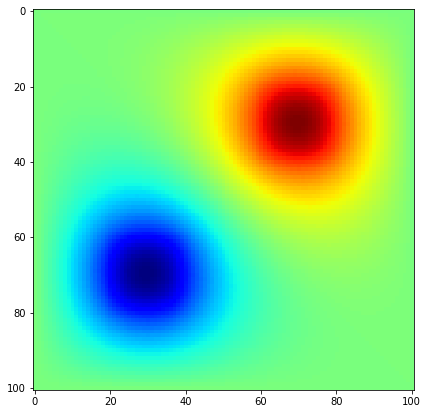

In [ ]:
def GaussSeidel_Poisson():
    
    # Constantes
    M = 100
    V = 1.0
    target = 1e-6
    dif = 1
    w = 0.9
    
    # Arrays necessários
    phi = np.zeros([M+1, M+1])
    rho = np.copy(phi)
    rho[20:40,60:80] = 1
    rho[60:80,20:40] = -1
    
    while dif > target:
        dif = 0
        
        for i in range(1,M):
            for j in range(1,M):
                
                diferenca = ( (phi[i+1,j] + phi[i-1,j] + phi[i,j+1] + phi[i,j-1])/4 + 1/4*rho[i,j] ) - phi[i,j]
                phi[i,j] = phi[i,j] + (1+w)*diferenca
                
                if diferenca > dif :
                    dif = diferenca
            
    plt.imshow(phi)
    plt.jet()
    plt.show()

GaussSeidel_Poisson()

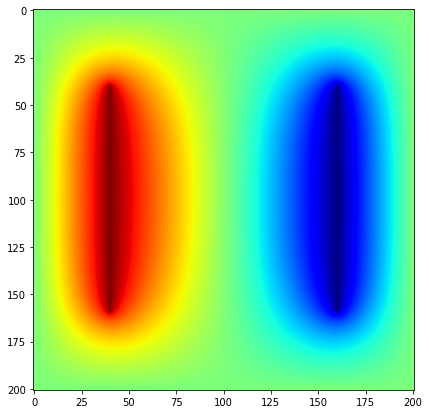

In [ ]:
def Capacitor():
    
    # Constantes
    M = 200
    V = 1.0
    target = 1e-6
    dif = 1
    w = 0.9
    
    phi = np.zeros([M+1, M+1])
    phi[40:160, 40] = V
    phi[40:160, 160] = -1.0 * V
    
    while dif > target:
        dif = 0
        
        for i in range(1,M):
            for j in range(1,M): 
                
                if (i >= 40 and i < 160 and j == 40) :
                    phi[i,j] = phi[i,j]
                
                else:
                    
                    if (i >= 40 and i < 160 and j == 160) :
                        phi[i,j] = phi[i,j]
                
                    else:   
                        diferenca = ( (phi[i+1,j] + phi[i-1,j] + phi[i,j+1] + phi[i,j-1])/4) - phi[i,j]
                        phi[i,j] = phi[i,j] + (1+w)*diferenca
                
                if diferenca > dif :
                    dif = diferenca
                
                
    plt.imshow(phi)
    plt.jet()
    plt.show()
    
Capacitor()

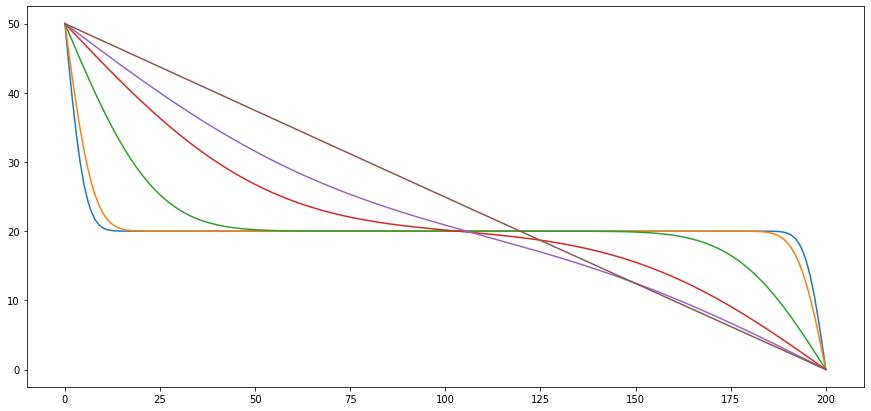

In [ ]:
def Heat(I):
    
    # Constantes
    # Espessura do metal
    L = 0.01   
    # Difusão Térmica
    D = 4.25e-6  
    # Número de intervalos
    N = 200       
    # Espaçamento na grelha
    a = L/N       
    # Time-step
    h = 1e-4
    epsilon = h/1000

    
    # Criar arrays para Temperatura
    T = np.ones(N+1)*20
    T[0] = 50
    T[-1] = 0   
    Tp = np.copy(T)
    
    t5 = 10.0
    tend = t5 + epsilon
    
    resultados = np.empty([100002, N+1])
    
    t = 0.0
    c = h*D/(a*a)
    it = 1
    while t<tend:
    
        # Calculate the new values of T
        Tp[1:N] = T[1:N] + c * ( T[2:N+1] + T[0:N-1] - 2*T[1:N]) 
        T,Tp = Tp,T
        t += h
    
        resultados[it,:] = T
        it += 1
                
    return resultados[I,:]

for i in [50,10**2,10**3,10**3*5,10**4,10**5]:
    plt.plot(Heat(i))
plt.show()